# 07 · Benchmark de engines: pandas × Polars × DuckDB × PySpark

**Coffee Big Data Intelligence**

> **Aviso central — leia antes de qualquer número:** este notebook separa **dois mundos**.
> **(1) Volume REAL** da cafeicultura/clima do projeto: **centenas de milhares de linhas**, cabe em qualquer notebook.
> **(2) Volume SINTÉTICO** (1M, 10M, 50M linhas): gerado aleatoriamente **apenas** para medir como as engines escalam. **Não representa volume real de café.** Chamar uma tabela pequena de *Big Data* só porque foi processada com Spark seria desonesto; por isso a pergunta aqui é: **a partir de qual escala o custo de uma engine distribuída se justifica?**

## Objetivos
1. Mostrar o **volume real** do projeto e quanto ele pesa em disco/memória.
2. Comparar as quatro engines em 4 operações, com **paridade de resultados** verificada.
3. Medir **tempo, pico de memória e custo de inicialização**, por processo isolado.
4. Estimar (**rotulado como extrapolação**) quando cada engine esgota um orçamento de memória.
5. Quantificar o efeito do **particionamento Parquet** e do problema de *arquivos pequenos*.
6. Demonstrar o gerador sintético com **limite de memória**.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from coffeebdi import config, silver, modeling as M, quality
from coffeebdi.lake import Lake
from coffeebdi.nbutils import duck, mpl_style

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40); pd.set_option("display.float_format", "{:,.2f}".format)
mpl_style()
lake = Lake()
con = duck(lake)
def q(sql):
    """Executa SQL (DuckDB) sobre as tabelas silver/gold e devolve DataFrame."""
    return con.execute(sql).df()
FIG = config.OUTPUTS / "figures"
import json, tempfile, time
from pathlib import Path
import psutil
from coffeebdi import synth, bench

## 1. Volume REAL do projeto

Contagem de linhas das tabelas efetivamente usadas (lago de dados local) e tamanho em disco por camada.

In [2]:
tabs = ["pam_municipio", "pam_uf", "dim_municipio", "conab_uf", "preco_cafe_mensal", "cambio_mensal", "ipca_mensal", "clima_diario",
        "clima_mensal", "clima_features", "painel_cafe_arabica"]
vol = pd.DataFrame([{"tabela": t, "linhas": int(q(f"select count(*) n from {t}").n[0]), "colunas": len(q(f"select * from {t} limit 0").columns)} for t in tabs]).set_index("tabela")
def du(p):
    p = Path(p); return sum(f.stat().st_size for f in p.rglob("*") if f.is_file()) / 1e6 if p.exists() else float("nan")
print("Tamanho em disco (MB):", {k: round(du(getattr(config, k)), 1) for k in ("BRONZE", "SILVER", "GOLD")})
print(f"Maior tabela real: {vol.linhas.idxmax()} com {vol.linhas.max():,} linhas")
vol

Tamanho em disco (MB): {'BRONZE': 17.2, 'SILVER': 6.8, 'GOLD': 1.0}
Maior tabela real: clima_diario com 759,760 linhas


,linhas,colunas
tabela,,
pam_municipio,51040,18
pam_uf,2160,14
dim_municipio,645,15
conab_uf,1812,7
preco_cafe_mensal,801,3
cambio_mensal,334,3
ipca_mensal,387,3
clima_diario,759760,8
clima_mensal,24960,11


**Como ler:** a maior tabela é o **clima diário** (80 células × ~9 500 dias). Tudo o mais tem milhares de linhas. Para café, o gargalo **não** é volume — é **qualidade, cobertura e número efetivo de safras**. O notebook 04 mostra que o número de observações *independentes* é ≈ 13 anos, não 1 663 linhas.

## 2. Metodologia do benchmark

| Item | Decisão | Por quê |
|---|---|---|
| Isolamento | **um subprocesso por (engine, operação, tamanho)** | evita cache e memória residual de uma engine contaminar a outra |
| Tempo | mediana de *k* repetições de **ler + calcular + escrever Parquet** | inclui I/O, que domina em colunar |
| Inicialização | medida **à parte** (`startup_s`) e fora da mediana | JVM/Spark tem custo fixo que a mediana esconderia |
| Memória | **pico de RSS da árvore de processos** (inclui a JVM) | medir só o Python subestimaria o Spark |
| Orçamento | 8 GB e 4 threads para todos; processo é **morto** se estourar | comparação justa em hardware idêntico |
| Paridade | resultados salvos em Parquet e **checksum** comparado entre engines | velocidade sem resultado igual não vale nada |
| pandas | lê **só as colunas necessárias**, `date_as_object=False` | evita desvantagem artificial por má prática |

Operações: `filter_count` (filtro + contagem por ano), `monthly_agg` (agregação célula×ano×mês), `join_agg` (junção com dimensão + agregação por UF×ano), `rolling_30d` (janela móvel de 30 dias por célula; a mais cara).

In [3]:
R = json.load(open(config.OUTPUTS / "benchmark_results.json"))
res = pd.DataFrame(R["results"])
print("Máquina:", R["system"]); print("Configuração:", R["config"])
print(f"Dados reais usados: {R['real_rows']:,} linhas, {R['real_cells']} células")
print("Divergências de paridade entre engines:", R["parity_issues"] or "nenhuma")
print("Status das execuções:", res.status.value_counts().to_dict())
ORDEM = ["REAL", "1M", "10M", "50M"]; ENG = ["pandas", "polars", "duckdb", "spark"]; OPS = bench.OPS
res["label"] = pd.Categorical(res.label, ORDEM, ordered=True)

Máquina: {'platform': 'macOS-15.8.2-arm64-arm-64bit', 'cpu_count': 14, 'ram_gb': 38.7, 'python': '3.11.9', 'pandas': '3.1.0', 'polars': '2.1.0', 'duckdb': '2.0.0', 'pyspark': '4.3.0'}
Configuração: {'threads': 4, 'mem_gb': 8.0, 'engines': ['pandas', 'polars', 'duckdb', 'spark']}
Dados reais usados: 759,760 linhas, 80 células
Divergências de paridade entre engines: nenhuma
Status das execuções: {'ok': 64}


## 3. Tempo por operação

Tempo mediano (tabela em milissegundos; gráfico em segundos) de uma execução completa, **excluindo** a inicialização da engine.

Tempo mediano em MILISSEGUNDOS:


engine               pandas   polars   duckdb     spark
op           label                                     
filter_count REAL      4.40     1.40    12.10    213.10
             1M        8.60     4.80    16.60    219.10
             10M      43.10    12.20    30.00    318.80
             50M     222.60    52.80    94.60  1,033.50
join_agg     REAL     38.60     5.90    16.30    332.20
             1M       50.70    13.40    33.10    328.00
             10M     421.10    63.60    80.10    473.80
             50M   2,257.70   335.50   306.80  1,397.70
monthly_agg  REAL     21.50     8.30    18.20    253.80
             1M       30.60    17.80    39.10    299.90
             10M     223.50    72.60   108.60    623.70
             50M   1,242.90   337.80   415.30  2,610.10
rolling_30d  REAL     64.20    17.70    40.40    615.90
             1M       87.10    21.40    58.10    753.40
             10M     965.90   261.10   387.00  4,792.80
             50M   5,346.50 1,437.10 1,742.30 23,397.40

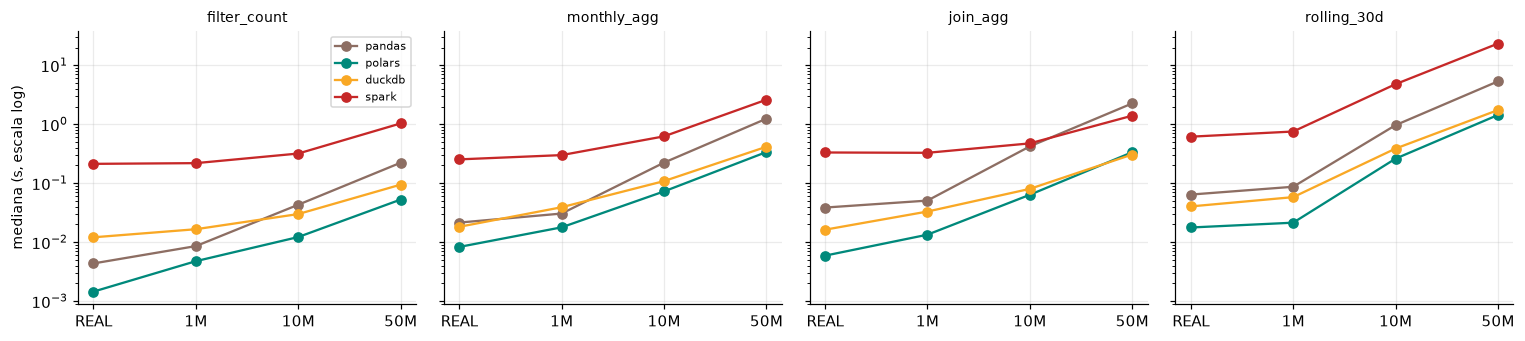

In [4]:
T = res.pivot_table(index=["op", "label"], columns="engine", values="median_s", observed=True)[ENG]
print("Tempo mediano em MILISSEGUNDOS:"); display((1000 * T).round(1))
fig, axs = plt.subplots(1, 4, figsize=(14, 3.2), sharey=True)
cores = {"pandas": "#8d6e63", "polars": "#00897b", "duckdb": "#f9a825", "spark": "#c62828"}
for a, op in zip(axs, OPS):
    t = T.loc[op].loc[ORDEM]
    for e in ENG: a.plot(range(len(t)), t[e], "o-", color=cores[e], label=e)
    a.set_xticks(range(len(t))); a.set_xticklabels(t.index); a.set_yscale("log"); a.set_title(op, fontsize=9)
axs[0].set_ylabel("mediana (s, escala log)"); axs[0].legend(fontsize=7)
plt.tight_layout(); plt.savefig(FIG / "07_tempos.png"); plt.show()

**Como ler:** escala **logarítmica**. REAL (≈0,76M linhas) fica no extremo esquerdo, ao lado de 1M. Duas observações verificáveis nos números: (i) em REAL, as engines locais terminam entre ~1 e ~65 ms; (ii) em nenhum tamanho testado (até 50M) o Spark ficou mais rápido que as engines locais **nesta máquina de nó único**. Isso **não** significa que Spark seja ruim: ele foi projetado para **dados maiores que a memória de uma máquina** e para **clusters**, o que **não foi testado aqui** (e não pode ser concluído a partir deste experimento).

### 3.1 Aceleração relativa (quanto mais lenta é cada engine em relação à mais rápida?)

Razão = tempo da engine / menor tempo entre as engines, na mesma operação e tamanho. Valores próximos de 1 = empate técnico.

In [5]:
RATIO = T.div(T.min(axis=1), axis=0)
display(RATIO.round(1))
print("Razão mediana por engine (todas as operações e tamanhos):"); print(RATIO.median().round(1).to_string())

engine              pandas  polars  duckdb  spark
op           label                               
filter_count REAL     3.00    1.00    8.30 147.10
             1M       1.80    1.00    3.50  46.10
             10M      3.50    1.00    2.50  26.10
             50M      4.20    1.00    1.80  19.60
join_agg     REAL     6.50    1.00    2.80  56.30
             1M       3.80    1.00    2.50  24.50
             10M      6.60    1.00    1.30   7.40
             50M      7.40    1.10    1.00   4.60
monthly_agg  REAL     2.60    1.00    2.20  30.60
             1M       1.70    1.00    2.20  16.80
             10M      3.10    1.00    1.50   8.60
             50M      3.70    1.00    1.20   7.70
rolling_30d  REAL     3.60    1.00    2.30  34.70
             1M       4.10    1.00    2.70  35.20
             10M      3.70    1.00    1.50  18.40
             50M      3.70    1.00    1.20  16.30

Razão mediana por engine (todas as operações e tamanhos):
engine
pandas    3.70
polars    1.00
duckdb    2.20
spark    22.00


**Como ler:** em tempos de milissegundos (REAL, 1M), razões como "5×" correspondem a diferenças de **frações de segundo** — irrelevantes para o usuário. A razão só importa quando o tempo absoluto importa: observe 50M e `rolling_30d`.

## 4. Memória e custo de inicialização

In [6]:
P = res.pivot_table(index=["op", "label"], columns="engine", values="peak_rss_gb", observed=True)[ENG]
display(P.round(2))
S = res.groupby(["engine"]).startup_s.median().round(2)
print("Mediana do tempo de inicialização (s):", S.to_dict())

engine              pandas  polars  duckdb  spark
op           label                               
filter_count REAL     0.17    0.11    0.07   0.87
             1M       0.18    0.10    0.07   1.13
             10M      0.46    0.18    0.13   1.57
             50M      1.13    0.27    0.19   2.56
join_agg     REAL     0.53    0.14    0.09   1.29
             1M       0.40    0.21    0.10   1.42
             10M      1.25    0.34    0.22   2.06
             50M      5.21    0.70    0.40   2.40
monthly_agg  REAL     0.51    0.13    0.10   1.07
             1M       0.49    0.16    0.10   1.22
             10M      1.41    0.45    0.30   1.92
             50M      5.66    0.67    0.60   2.31
rolling_30d  REAL     0.41    0.22    0.20   1.12
             1M       0.50    0.23    0.20   1.08
             10M      1.70    0.75    0.61   1.49
             50M      6.43    2.82    1.78   2.62

Mediana do tempo de inicialização (s): {'duckdb': 0.04, 'pandas': 0.28, 'polars': 0.08, 'spark': 3.34}


**Como ler:** `peak_rss_gb` é o pico da **árvore de processos**. Duas fontes de custo fixo: a JVM (Spark paga ~3 s e centenas de MB **mesmo para dados minúsculos**) e a importação das bibliotecas Python. Em REAL, a inicialização do Spark equivale a **~5 a ~16 vezes** o tempo de uma operação (seção 5).

### 4.1 Extrapolação do uso de memória (**ESTIMATIVA, não medição**)

Com 3 tamanhos sintéticos (1M, 10M, 50M) ajusta-se, por (engine, operação), uma reta `pico = a + b · linhas`. Isso permite estimar **qual tamanho estouraria um orçamento de memória** — **extrapolação linear com 3 pontos**: serve para ordem de grandeza, não para planejamento fino. O RSS do Spark reflete a política de *heap* da JVM e ele pode fazer *spill* em disco: a reta **não** é um limite real para ele (e seu valor extrapolado menor que o de DuckDB/Polars não significa que processe menos dados).

In [7]:
rows = []
NR = {"1M": 1e6, "10M": 1e7, "50M": 5e7}
for (e, op), g in res[res.label.isin(NR)].groupby(["engine", "op"], observed=True):
    x = np.array([NR[l] for l in g.label]); y = g.peak_rss_gb.values
    b, a = np.polyfit(x, y, 1); r2 = np.corrcoef(x, y)[0, 1] ** 2
    budget = R["config"]["mem_gb"]
    rows.append({"engine": e, "op": op, "bytes/linha (b)": b * 1e9, "base_GB (a)": a, "R²": r2,
                 "linhas no orçamento de 8 GB (milhões, EXTRAPOLADO)": (budget - a) / b / 1e6 if b > 0 else np.inf})
ext = pd.DataFrame(rows).set_index(["op", "engine"]).sort_index()
ext.round(2)

bytes/linha (b)  base_GB (a)   R²  linhas no orçamento de 8 GB (milhões, EXTRAPOLADO)
op           engine                                                                                       
filter_count duckdb             2.25         0.08 0.88                                           3,521.76 
             pandas            18.44         0.22 0.99                                             422.22 
             polars             3.05         0.12 0.92                                           2,583.34 
             spark             27.73         1.19 0.98                                             245.66 
join_agg     duckdb             5.67         0.13 0.94                                           1,389.96 
             pandas            98.44         0.28 1.00                                              78.39 
             polars             9.72         0.22 0.99                                             800.73 
             spark             16.56         1.62 0.75                                             385.19 
monthly_agg  duckdb             9.26         0.15 0.95                                             848.44 
             pandas           105.83         0.37 1.00                                              72.14 
             polars             8.90         0.25 0.83                                             871.43 
             spark             18.37         1.44 0.76                                             357.09 
rolling_30d  duckdb            31.36         0.22 0.99                                             247.96 
             pandas           120.09         0.43 1.00                                              63.00 
             polars            52.52         0.20 1.00                                             148.52 
             spark             30.51         1.11 0.99                                             225.86

**Como ler:** `bytes/linha` é a inclinação da reta (custo marginal por linha); `base_GB` é o custo fixo. Um R² baixo ou um limite estimado muito diferente do medido sinalizam que a reta é **inadequada**. Em pandas, as quatro operações têm o menor limite estimado (63–422 milhões de linhas; `rolling_30d`, `monthly_agg` e `join_agg` ficam em ~63–78 milhões): é onde o processo seria morto primeiro pelo orçamento do harness, comportamento esperado de quem carrega tudo em RAM com cópias intermediárias.

## 5. Real × sintético: o que o benchmark permite concluir?

In [8]:
real = res[res.label == "REAL"].pivot_table(index="op", columns="engine", values="median_s", observed=True)[ENG]
fator = 50_000_000 / R["real_rows"]
print(f"O maior conjunto sintético (50M) tem {fator:,.0f}× as linhas do conjunto REAL ({R['real_rows']:,}).")
print("\nREAL — tempo mediano (ms):"); display((1000 * real).round(1))
ini = res.groupby("engine").startup_s.median()
razao = pd.DataFrame({e: ini[e] / real[e] for e in ENG}).round(1)
print("Inicialização da engine ÷ tempo de UMA operação no REAL (por operação):"); display(razao)

O maior conjunto sintético (50M) tem 66× as linhas do conjunto REAL (759,760).

REAL — tempo mediano (ms):


engine,pandas,polars,duckdb,spark
op,,,,
filter_count,4.40,1.40,12.10,213.10
join_agg,38.60,5.90,16.30,332.20
monthly_agg,21.50,8.30,18.20,253.80
rolling_30d,64.20,17.70,40.40,615.90


Inicialização da engine ÷ tempo de UMA operação no REAL (por operação):


,pandas,polars,duckdb,spark
op,,,,
filter_count,64.70,55.90,3.30,15.70
join_agg,7.30,13.70,2.40,10.10
monthly_agg,13.10,9.80,2.20,13.20
rolling_30d,4.40,4.60,1.00,5.40


**Conclusão defensável (e só ela):**

1. Para o volume **real** deste projeto, **pandas, Polars ou DuckDB** resolvem tudo em milissegundos. **Spark é custo sem benefício** nesse volume (a inicialização equivale a ~5–16 vezes o tempo de uma operação; para pandas e Polars, só importar a biblioteca já custa de ~4 a ~65 vezes o cálculo de uma operação em REAL).
2. Para **tabelas sintéticas de até 50M linhas em uma máquina de 14 núcleos e ~39 GB**, as engines locais continuam à frente. O ponto de virada do Spark **não foi atingido**; ele estaria em volumes maiores que a memória de um nó ou em cluster — **cenário não medido**.
3. **DuckDB e Polars** ficaram consistentemente entre as mais rápidas e com pouca memória, por serem colunares, vetorizadas e com execução *lazy*/pushdown. pandas funciona, mas carrega os dados em RAM e tem o maior custo de memória por linha (≈18–120 bytes/linha contra ≈2–52 de DuckDB/Polars).

Um projeto de café só passaria a precisar de engine distribuída se agregasse **séries de alta resolução** (ex.: milhões de pontos por talhão/sensor, imagens de satélite por pixel e data) — dados que **este projeto não usa**.

## 6. Particionamento Parquet (hive) e o problema dos arquivos pequenos

Experimento com 10M linhas sintéticas: filtro por `ano = 2015` e leitura total, em (a) arquivo único, (b) particionado por `ano` (14 arquivos), (c) particionado por `ano, mes` (165 arquivos).

In [9]:
pt = json.load(open(config.OUTPUTS / "benchmark_partition.json"))
part = pd.DataFrame({
    "layout": ["arquivo único", "partição ano", "partição ano/mês"],
    "arquivos": [1, pt["n_arquivos_ano"], pt["n_arquivos_ano_mes"]],
    "filtro ano=2015 (ms)": 1000 * np.array([pt["arquivo_unico_filtro_ano"], pt["part_ano_filtro_ano"], pt["part_ano_mes_filtro_ano"]]),
    "leitura total (ms)": 1000 * np.array([pt["arquivo_unico_scan_total"], pt["part_ano_scan_total"], pt["part_ano_mes_scan_total"]])}).set_index("layout")
part.round(1)

,arquivos,filtro ano=2015 (ms),leitura total (ms)
layout,,,
arquivo único,1,17.40,18.90
partição ano,14,7.40,25.40
partição ano/mês,165,12.80,27.00


**Como ler:** a partição por `ano` acelera o **filtro** que usa essa coluna (o motor pula arquivos inteiros — *partition pruning*) e deixa a **leitura total** ligeiramente mais lenta (mais arquivos para abrir). Particionar por `ano/mês` (165 arquivos) fica **pior que por `ano`** nos dois testes (ainda melhor que o arquivo único no filtro, mas com a leitura total mais lenta): é o início do problema dos **arquivos pequenos**, que se agrava com mais partições. Regra prática: arquivos de dezenas a centenas de MB e partições por colunas de **baixa cardinalidade** usadas em filtros. **Os tempos aqui são de milissegundos**; o efeito é qualitativo — com dados reais deste projeto, particionar é **desnecessário** e mantido só como prática demonstrativa (por UF/ano nas tabelas silver).

## 7. Gerador sintético com limite de memória

O gerador escreve em **blocos**: o pico de memória depende do tamanho do bloco, **não** do total de linhas. O parâmetro `max_mem_gb` define o bloco (25% do limite, máx. 5M linhas).

In [10]:
print("Linhas por bloco conforme o limite de memória:")
print(pd.Series({f"{g} GB": synth.chunk_rows_for_memory(g) for g in (0.1, 0.5, 2, 8, 32)}, name="linhas/bloco").to_string())
import subprocess, sys
SRC = str(Path(synth.__file__).resolve().parents[1])
rows = []
with tempfile.TemporaryDirectory() as td:
    for lim in (0.1, 0.5, 2.0):
        code = f"from coffeebdi import synth; i = synth.generate(10_000_000, r'{td}/s_{lim}.parquet', seed=1, max_mem_gb={lim}); print(i['bytes'], i['seconds'])"
        p = subprocess.Popen([sys.executable, "-I", "-c", code], env={**__import__("os").environ, "PYTHONPATH": SRC}, stdout=subprocess.PIPE, stderr=subprocess.DEVNULL, text=True)
        ps = psutil.Process(p.pid); peak = 0
        while p.poll() is None:
            try: peak = max(peak, ps.memory_info().rss)
            except psutil.Error: break
            time.sleep(0.01)
        by, sec = p.stdout.read().split()[-2:]
        rows.append({"limite max_mem_gb": lim, "linhas/bloco": synth.chunk_rows_for_memory(lim), "arquivo (MB)": int(by) / 1e6, "tempo (s)": float(sec), "pico RSS do processo (MB)": peak / 1e6})
pd.DataFrame(rows).set_index("limite max_mem_gb").round(1)

Linhas por bloco conforme o limite de memória:
0.1 GB     640000
0.5 GB    3205000
2 GB      5000000
8 GB      5000000
32 GB     5000000


,linhas/bloco,arquivo (MB),tempo (s),pico RSS do processo (MB)
limite max_mem_gb,,,,
0.10,640000,107.00,1.50,371.50
0.50,3205000,103.00,1.40,485.20
2.00,5000000,100.30,1.40,606.60


**Como ler:** cada limite roda em **processo próprio** (medir dois limites no mesmo processo se confunde com a memória que o alocador já reservou). Compare `pico RSS` com `linhas/bloco`: bloco menor ⇒ pico menor (aqui ≈325 → 489 → 604 MB), **sem custo mensurável de tempo** nesta máquina (≈1,4 s nos três casos). Atenção: o sorteio aleatório é feito por bloco, então tamanhos de bloco diferentes geram dados *diferentes* (o determinismo vale para o par semente + limite de memória, e o tamanho do arquivo varia ~7%). O gerador respeita o **orçamento** pedido; o RSS inclui o interpretador e as bibliotecas (≈100–200 MB fixos), então para limites muito pequenos o piso é o próprio Python. O arquivo traz o metadado Parquet `synthetic=true`, para que nenhum leitor confunda este dado com volume real. **Nunca** apresente estes números como produção cafeeira.

## 8. Reexecução ao vivo (opcional, 1M linhas)

Para validar a **reprodutibilidade**: repete-se, agora, `filter_count` e `monthly_agg` em 1M linhas para as três engines locais (Spark fica de fora: seu custo de inicialização já foi medido nas seções 3–4). Diferenças pequenas em relação à tabela da seção 3 refletem **ruído da máquina** (outros processos, térmica).

In [11]:
src = config.SYNTH / "SYNTH_clima_1M.parquet"
if src.exists():
    live = []
    for op in ("filter_count", "monthly_agg"):
        for e in ("pandas", "polars", "duckdb"):
            r = bench.run_one(e, op, src, src.with_name(src.stem + "_dim_cell.parquet"), threads=4, mem_gb=8.0, reps=5, timeout_s=300)
            live.append({"op": op, "engine": e, "status": r["status"], "mediana ao vivo (s)": r.get("median_s", np.nan)})
    live = pd.DataFrame(live).merge(res[res.label == "1M"][["op", "engine", "median_s"]].rename(columns={"median_s": "mediana gravada (s)"}), on=["op", "engine"])
    display(live.round(4))
else:
    print("Arquivo sintético 1M ausente — gere com: python scripts/run_benchmark.py (não afeta o restante do projeto).")

,op,engine,status,mediana ao vivo (s),mediana gravada (s)
0,filter_count,pandas,ok,0.01,0.01
1,filter_count,polars,ok,0.00,0.00
2,filter_count,duckdb,ok,0.02,0.02
3,monthly_agg,pandas,ok,0.03,0.03
4,monthly_agg,polars,ok,0.02,0.02
5,monthly_agg,duckdb,ok,0.04,0.04


## 9. Resumo interpretativo

| Pergunta | Resposta | Evidência / limite |
|---|---|---|
| O projeto é "Big Data" em volume? | **Não**: ≈0,76M linhas na maior tabela | seção 1 |
| Qual engine usar para os dados reais? | qualquer uma local; DuckDB/Polars por ergonomia e memória | seção 3, 5 |
| Spark é mais rápido em 50M? | **Não** nesta máquina de nó único | seção 3; cluster **não testado** |
| Quando faria sentido Spark? | dados maiores que a RAM ou cluster; **não medido aqui** | seção 5 |
| Particionar ajuda? | ajuda filtros pela coluna de partição; arquivos pequenos prejudicam | seção 6 (milissegundos) |
| As engines dão o mesmo resultado? | sim, checksum igual em todas as execuções | seção 2 |

**Limites do benchmark:** uma única máquina (macOS, arm64, 14 núcleos, ~39 GB); dados sintéticos com distribuição simples; 4 operações; SSD local. Resultados em outro hardware, com disco em rede ou dados com chaves de alta cardinalidade **podem inverter** o ranking.

## Exercícios
1. Gere um sintético de 100M linhas com `max_mem_gb=4` e rode `monthly_agg` em DuckDB e pandas: o pandas ultrapassa o orçamento de 8 GB? O que o harness registra?
2. Rode o benchmark com `BENCH_THREADS=1` e `=8`: qual engine escala melhor com threads?
3. Reparticione o sintético de 10M por `cell_id` (alta cardinalidade) e meça o filtro por ano. O que acontece?
4. Por que medir `startup_s` separado da mediana muda a conclusão para dados pequenos?
5. A extrapolação linear de memória é confiável para `rolling_30d` em Spark? Justifique.